# Superstore Profit Leakage: Discounts, Product Mix and a Discount-Cap Policy

**Business question.** An office-supplies retailer sold about $14.9M over 2009–2012, yet its margin is slipping and half of its
order lines lose money. Where is profit leaking, and what discount policy would recover it without losing too many sales?

**Data.** 8,399 order lines from the Tableau *Superstore Sales* sample (Canada, 2009–2012): sales, discount, profit, product, ship mode, customer segment.

**Approach.**
1. KPI baseline and trend (SQL)
2. Profit by sub-category and loss-making order lines (SQL)
3. Discount impact, **adjusted for product mix** so the result is not just "Tables are discounted and unprofitable" (SQL)
4. Ship mode and order priority checks
5. Discount-cap scenario model with a price-elasticity assumption, plus break-even prices for loss-making products
6. Export of the same model to Excel (`excel/discount_policy_model.xlsx`) with live formulas for stakeholders

In [1]:
import re
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

sys.path.append("../src")
from discount_model import apply_discount_cap, scenario_summary
from style import C, BLUES, apply_style, save

apply_style()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

SQL = Path("../sql/analysis_queries.sql").read_text()
QUERIES = dict(re.findall(r"-- name: (\w+)\n(.*?)(?=\n-- name: |\Z)", SQL, flags=re.S))


def q(name):
    return con.execute(QUERIES[name]).df()

## 1. Load and clean

In [2]:
raw = pd.read_csv("../data/raw/superstore.csv", encoding="latin-1")  # file uses CR line endings and Latin-1
orders = raw.rename(columns={
    "Order ID": "order_id", "Order Date": "order_date", "Order Priority": "order_priority",
    "Order Quantity": "quantity", "Sales": "sales", "Discount": "discount", "Ship Mode": "ship_mode",
    "Profit": "profit", "Unit Price": "unit_price", "Shipping Cost": "shipping_cost",
    "Customer Name": "customer", "Province": "province", "Region": "region", "Customer Segment": "segment",
    "Product Category": "category", "Product Sub-Category": "sub_category", "Product Name": "product",
})[["order_id", "order_date", "order_priority", "quantity", "sales", "discount", "ship_mode", "profit",
    "unit_price", "shipping_cost", "customer", "province", "region", "segment", "category", "sub_category", "product"]]
orders["order_date"] = pd.to_datetime(orders["order_date"], format="%m/%d/%Y")
orders["discount_band"] = pd.cut(orders["discount"], [-0.001, 0, 0.03, 0.06, 0.09, 1],
                                 labels=["a) 0%", "b) 1-3%", "c) 4-6%", "d) 7-9%", "e) 10%+"]).astype(str)

print(f"Order lines: {len(orders):,} | orders: {orders.order_id.nunique():,} | customers: {orders.customer.nunique():,}")
print(f"Period: {orders.order_date.min():%d %b %Y} to {orders.order_date.max():%d %b %Y}")
print(f"Duplicate rows: {raw.duplicated().sum()} | missing values in used columns: {orders.isna().sum().sum()}")

con = duckdb.connect()
con.register("orders", orders);

Order lines: 8,399 | orders: 5,496 | customers: 795
Period: 01 Jan 2009 to 30 Dec 2012
Duplicate rows: 0 | missing values in used columns: 0


## 2. KPI baseline

In [3]:
kpi = q("kpi_by_year")
total_sales, total_profit = orders["sales"].sum(), orders["profit"].sum()
print(f"Total sales ${total_sales/1e6:.2f}M | profit ${total_profit/1e6:.2f}M | margin {total_profit/total_sales:.1%}")
kpi

Total sales $14.92M | profit $1.52M | margin 10.2%


,year,order_lines,sales,profit,margin_pct,avg_discount_pct
0,2009,2153,"4,209,139.00","434,539.00",10.30,4.89
1,2010,2142,"3,549,681.00","363,871.00",10.30,4.94
2,2011,2002,"3,436,817.00","381,456.00",11.10,5.08
3,2012,2102,"3,719,964.00","341,902.00",9.20,4.97


## 3. Where is profit lost?

In [4]:
loss = q("loss_lines")
loss

,loss_lines,loss_line_pct,total_losses,total_gains,net_profit
0,4264,50.80,"-1,102,503.00","2,624,271.00","1,521,768.00"


In [5]:
sub = q("subcategory_profit")
sub

,category,sub_category,order_lines,sales,profit,margin_pct,loss_line_pct
0,Furniture,Tables,361,"1,896,008.00","-99,063.00",-5.20,71.50
1,Furniture,Bookcases,189,"822,652.00","-33,582.00",-4.10,78.30
2,Office Supplies,"Scissors, Rulers and Trimmers",144,"80,996.00","-7,799.00",-9.60,76.40
3,Office Supplies,Rubber Bands,179,"15,007.00",-103.00,-0.70,55.90
4,Office Supplies,Storage & Organization,546,"1,070,183.00","6,664.00",0.60,69.40
5,Office Supplies,Pens & Art Supplies,633,"167,107.00","7,565.00",4.50,47.70
6,Office Supplies,Labels,288,"38,982.00","13,677.00",35.10,11.50
7,Office Supplies,Paper,1225,"446,453.00","45,263.00",10.10,59.30
8,Office Supplies,Envelopes,246,"174,086.00","48,183.00",27.70,29.30
9,Technology,Computer Peripherals,758,"795,876.00","94,287.00",11.80,53.80


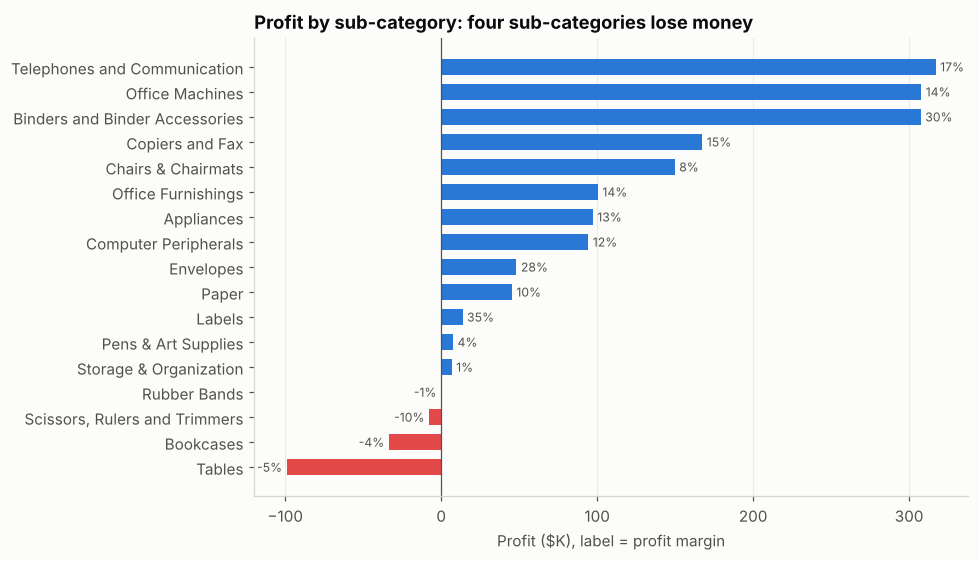

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.2))
s = sub.sort_values("profit")
colors = [C["red"] if p < 0 else C["blue"] for p in s["profit"]]
bars = ax.barh(s["sub_category"], s["profit"] / 1e3, color=colors, height=0.65)
ax.bar_label(bars, labels=[f"{m:.0f}%" for m in s["margin_pct"]], padding=3, fontsize=8, color=C["ink2"])
ax.axvline(0, color=C["ink2"], lw=0.8)
ax.set_xlabel("Profit ($K), label = profit margin")
ax.set_title("Profit by sub-category: four sub-categories lose money")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
save(fig, "01_profit_by_subcategory")
plt.show()

## 4. Do discounts destroy margin?
Raw margins fall as discounts rise, but that could simply be product mix (low-margin furniture gets bigger discounts).
The mix-adjusted query compares high- vs low-discount lines **inside each sub-category** and then weights by sales.

In [7]:
band = q("margin_by_discount_band")
band

,discount_band,order_lines,sales,margin_pct
0,a) 0%,756,"1,493,748.00",12.60
1,b) 1-3%,2350,"4,185,575.00",13.60
2,c) 4-6%,2290,"4,050,805.00",8.40
3,d) 7-9%,2253,"4,038,512.00",8.60
4,e) 10%+,750,"1,146,961.00",6.40


In [8]:
mix = q("mix_adjusted_discount_effect")
mix

,margin_low_disc_pct,margin_high_disc_pct,mix_adjusted_gap_pp,subcats_where_discount_hurts,subcats
0,11.90,7.60,-4.40,15,17


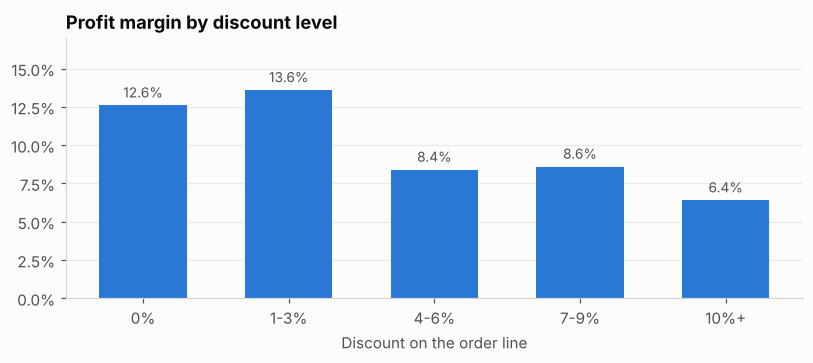

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
b = band[band["order_lines"] >= 100]
labels = b["discount_band"].str.replace(r"^[a-e]\) ", "", regex=True)
bars = ax.bar(labels, b["margin_pct"] / 100, color=C["blue"], width=0.6)
ax.bar_label(bars, labels=[f"{m:.1f}%" for m in b["margin_pct"]], padding=3, fontsize=9, color=C["ink2"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 0.17)
ax.set_xlabel("Discount on the order line")
ax.set_title("Profit margin by discount level")
save(fig, "02_margin_by_discount")
plt.show()

## 5. Ship mode and order priority
Delivery Truck is used for bulky furniture (tables, bookcases), and that furniture barely breaks even. The cause is the product,
not the truck: Technology shipped by truck still earns a healthy margin.

In [10]:
ship = q("shipping_by_mode")
ship.pivot(index="ship_mode", columns="category", values="margin_pct")

category,Furniture,Office Supplies,Technology
ship_mode,,,
Delivery Truck,-0.20,1.30,15.80
Express Air,12.90,13.80,11.20
Regular Air,12.10,15.30,14.90


In [11]:
q("priority_margin")

,order_priority,order_lines,margin_pct
0,Critical,1608,6.70
1,Not Specified,1672,7.90
2,Medium,1631,11.40
3,Low,1720,11.80
4,High,1768,12.50


## 6. Scenario: cap discounts
**Model** (in `src/discount_model.py`): capping a line's discount raises the price the customer pays by
`r = (1 - new discount) / (1 - old discount)`. Volume responds through a price elasticity `e`
(e = -2 means a 1% price rise loses 2% of units). Unit cost is unchanged, so new profit = (old profit + extra revenue) × volume factor.

The grid below tests caps from 3% to 8% and elasticities from -1 (insensitive) to -4 (very price-sensitive).

In [12]:
caps = [0.03, 0.04, 0.05, 0.06, 0.08]
elasticities = [-1, -2, -3, -4]
grid = pd.DataFrame(
    [[scenario_summary(orders, c, e)["profit_uplift"] for c in caps] for e in elasticities],
    index=[f"e = {e}" for e in elasticities], columns=[f"cap {c:.0%}" for c in caps],
)
(grid / 1e3).round(0).astype(int).astype(str).radd("$").add("K")

,cap 3%,cap 4%,cap 5%,cap 6%,cap 8%
e = -1,$341K,$258K,$185K,$124K,$37K
e = -2,$289K,$221K,$161K,$109K,$34K
e = -3,$236K,$184K,$136K,$94K,$30K
e = -4,$183K,$147K,$112K,$78K,$26K


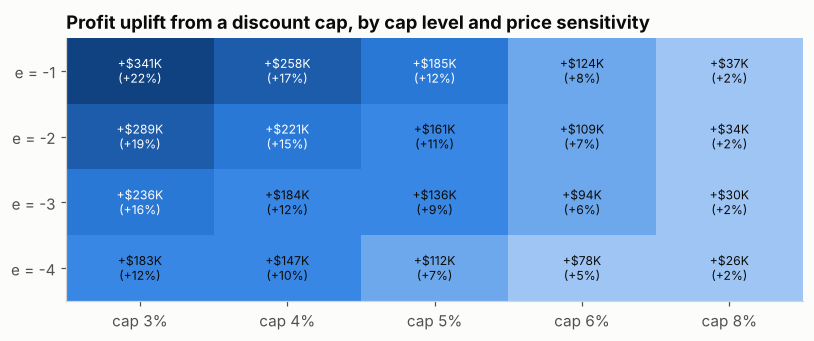

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
im = ax.imshow(grid.values / total_profit, cmap=plt.matplotlib.colors.ListedColormap(BLUES[1:7]), aspect="auto")
ax.set_xticks(range(len(caps)), grid.columns)
ax.set_yticks(range(len(elasticities)), grid.index)
for i in range(len(elasticities)):
    for j in range(len(caps)):
        v = grid.values[i, j]
        ax.text(j, i, f"+${v/1e3:.0f}K\n(+{v/total_profit:.0%})", ha="center", va="center", fontsize=8,
                color="white" if (v - grid.values.min()) / (grid.values.max() - grid.values.min()) >= 0.5 else C["ink"])
ax.grid(False)
ax.set_title("Profit uplift from a discount cap, by cap level and price sensitivity")
save(fig, "03_discount_cap_grid")
plt.show()

**Recommended policy: cap discounts at 5%.** The base case uses e = -2. Results are shown for the whole catalogue and for
Technology + Office Supplies only (furniture excluded, in case sales teams need discount room for large furniture deals).

In [14]:
CAP, E = 0.05, -2
base = scenario_summary(orders, CAP, E)
no_furn = scenario_summary(orders, CAP, E, in_scope=orders.loc[orders.category != "Furniture", "sub_category"].unique())
affected = (orders["discount"] > CAP).mean()
for name, r in [("All sub-categories", base), ("Excluding furniture", no_furn)]:
    print(f"{name:<22} profit uplift ${r['profit_uplift']/1e3:,.0f}K (+{r['profit_uplift']/total_profit:.1%}) "
          f"| sales change {r['sales_change']/total_sales:+.1%}")
print(f"Share of order lines affected by a {CAP:.0%} cap: {affected:.0%}")

All sub-categories     profit uplift $161K (+10.6%) | sales change -1.5%
Excluding furniture    profit uplift $94K (+6.2%) | sales change -1.0%
Share of order lines affected by a 5% cap: 44%


### Break-even prices for loss-making sub-categories
Even at low discounts, Tables and Bookcases lose money. The price rise needed to bring each loss-maker to zero margin
(holding volume constant) tells the category team how far off the price is.

In [15]:
loss_subs = sub[sub["profit"] < 0].copy()
loss_subs["price_rise_to_break_even_pct"] = (-loss_subs["profit"] / loss_subs["sales"] * 100).round(1)
loss_subs[["sub_category", "sales", "profit", "margin_pct", "price_rise_to_break_even_pct"]]

,sub_category,sales,profit,margin_pct,price_rise_to_break_even_pct
0,Tables,"1,896,008.00","-99,063.00",-5.20,5.20
1,Bookcases,"822,652.00","-33,582.00",-4.10,4.10
2,"Scissors, Rulers and Trimmers","80,996.00","-7,799.00",-9.60,9.60
3,Rubber Bands,"15,007.00",-103.00,-0.70,0.70


## 7. Export the model to Excel
`src/build_excel_model.py` writes all order lines with **live formulas**: stakeholders change the cap, the elasticity and the
per-sub-category on/off switch on the Inputs sheet and the Summary sheet updates. With the default inputs (5% cap, e = -2,
all sub-categories on), the workbook's Summary should show the same totals as the Python model printed below.

In [16]:
import subprocess
out = subprocess.run([sys.executable, "../src/build_excel_model.py"], capture_output=True, text=True)
print(out.stdout.strip() or out.stderr[-800:])
print(f"Expected in Excel -> profit with cap: ${base['profit']:,.0f} | uplift: ${base['profit_uplift']:,.0f} "
      f"({base['profit_uplift']/total_profit:.1%}) | sales change: {base['sales_change']/total_sales:+.1%}")

Wrote excel/discount_policy_model.xlsx: 8,399 order lines with live formulas, 17 sub-category switches.
Expected in Excel -> profit with cap: $1,682,540 | uplift: $160,772 (10.6%) | sales change: -1.5%


## 8. Findings

In [17]:
k = kpi.set_index("year")
print(f"""
- ${total_sales/1e6:.2f}M sales and ${total_profit/1e6:.2f}M profit ({total_profit/total_sales:.1%} margin) over 2009-2012;
  margin slipped from {k.loc[2009,'margin_pct']}% (2009) to {k.loc[2012,'margin_pct']}% (2012).
- {loss.loc[0,'loss_line_pct']}% of order lines lose money: ${-loss.loc[0,'total_losses']/1e6:.2f}M of losses offset
  ${loss.loc[0,'total_gains']/1e6:.2f}M of gains.
- {len(loss_subs)} sub-categories are loss-making overall (${-loss_subs['profit'].sum()/1e3:.0f}K combined); Tables alone lose
  ${-sub.set_index('sub_category').loc['Tables','profit']/1e3:.0f}K.
- Lines discounted above 5% earn {abs(mix.loc[0,'mix_adjusted_gap_pp'])} pp less margin than low-discount lines in the same
  sub-category ({mix.loc[0,'subcats_where_discount_hurts']} of {mix.loc[0,'subcats']} sub-categories).
- A {CAP:.0%} discount cap (e = {E}) adds about ${base['profit_uplift']/1e3:,.0f}K profit (+{base['profit_uplift']/total_profit:.1%})
  for a {base['sales_change']/total_sales:+.1%} change in sales; it affects {affected:.0%} of order lines.
""")


- $14.92M sales and $1.52M profit (10.2% margin) over 2009-2012;
  margin slipped from 10.3% (2009) to 9.2% (2012).
- 50.8% of order lines lose money: $1.10M of losses offset
  $2.62M of gains.
- 4 sub-categories are loss-making overall ($141K combined); Tables alone lose
  $99K.
- Lines discounted above 5% earn 4.4 pp less margin than low-discount lines in the same
  sub-category (15 of 17 sub-categories).
- A 5% discount cap (e = -2) adds about $161K profit (+10.6%)
  for a -1.5% change in sales; it affects 44% of order lines.

